# 03 — Baseline Models: Dummy and Logistic Regression

**Protocol**
- **Tuning:** 5-fold stratified CV on the training set (18,000 rows), scored by average precision.
- **Fitting:** each tuned pipeline is refitted on the full training set.
- **Evaluation:** on the validation set (6,000 rows), with the decision threshold chosen by maximising **F2** (recall weighted more than precision).
- **The test set is not used.**

Results are loaded from `artifacts/metrics/`, which `scripts/run_experiments.py` writes. Nothing in this notebook is recomputed by hand.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from credit_risk.config import load_config, resolve_path
BLUE, ORANGE, AQUA, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a9a", "#1f1f1f", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "axes.axisbelow": True, "figure.dpi": 110})
FIG_DIR = resolve_path("reports/figures")
pd.set_option("display.width", 160); pd.set_option("display.precision", 4)
M = resolve_path("artifacts/metrics")
records = {p.stem: r for p in M.glob("*.json") if p.stem not in {"summary", "comparisons", "selection"}
           for r in [json.loads(p.read_text())] if r.get("evaluated_on") == "validation" and "model" in r}
ORDER = ["dummy_prior", "logreg_raw", "logreg", "logreg_balanced"]
COLOR = {"dummy_prior": GREY, "logreg_raw": ORANGE, "logreg": BLUE, "logreg_balanced": AQUA}
summary = pd.DataFrame(json.loads((M / "summary.json").read_text())["models"]).set_index("model").loc[ORDER]
summary[["roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "pr_auc", "brier", "log_loss",
         "expected_calibration_error", "mean_predicted_pd", "threshold", "precision", "recall", "f1", "f2", "flagged_rate"]]

,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,brier,log_loss,expected_calibration_error,mean_predicted_pd,threshold,precision,recall,f1,f2,flagged_rate
model,,,,,,,,,,,,,,
dummy_prior,0.5000,0.5000,0.5000,0.2212,0.1723,0.5284,0.0208,0.2212,0.01,0.2212,1.0000,0.3622,0.5868,1.0000
logreg_raw,0.7732,0.7588,0.7872,0.5452,0.1357,0.4337,0.0177,0.2179,0.12,0.3138,0.8583,0.4596,0.6372,0.6050
logreg,0.7798,0.7651,0.7938,0.5473,0.1345,0.4299,0.0165,0.2184,0.11,0.3054,0.8832,0.4539,0.6408,0.6395
logreg_balanced,0.7800,0.7654,0.7941,0.5447,0.1799,0.5498,0.2057,0.4268,0.31,0.3143,0.8696,0.4617,0.6425,0.6120


In [2]:
pd.DataFrame({m: {**records[m]["cv"]["best_params"], "cv_ap_mean": records[m]["cv"].get("best_cv_score_mean"),
                  "cv_ap_std": records[m]["cv"].get("best_cv_score_std")} for m in ORDER}).T

,cv_ap_mean,cv_ap_std,C
dummy_prior,0.2212,0.0001,NaN
logreg_raw,0.5513,0.0171,1.0
logreg,0.5478,0.0144,1.0
logreg_balanced,0.5442,0.0155,NaN


## Paired comparisons (validation, 1,000 bootstrap resamples)

In [3]:
comp = pd.DataFrame(json.loads((M / "comparisons.json").read_text()))
comp = comp[comp.model_a.eq("logreg") & ~comp.model_b.str.contains("__")]
comp[["model_a", "model_b", "metric", "difference", "low", "high", "p_value_two_sided"]]

,model_a,model_b,metric,difference,low,high,p_value_two_sided
0,logreg,logreg_raw,roc_auc,0.0066,0.0034,0.0102,0.000
1,logreg,logreg_raw,pr_auc,0.0022,-0.0033,0.0079,0.416
2,logreg,logreg_raw,brier,-0.0012,-0.0020,-0.0005,0.000
3,logreg,dummy_prior,roc_auc,0.2798,0.2651,0.2938,0.000
4,logreg,dummy_prior,pr_auc,0.3262,0.3005,0.3538,0.000
5,logreg,dummy_prior,brier,-0.0377,-0.0420,-0.0333,0.000
12,logreg,logreg_balanced,roc_auc,-0.0002,-0.0014,0.0010,0.712
13,logreg,logreg_balanced,pr_auc,0.0026,0.0003,0.0052,0.030
14,logreg,logreg_balanced,brier,-0.0454,-0.0497,-0.0412,0.000


## Discrimination: ROC and precision–recall curves

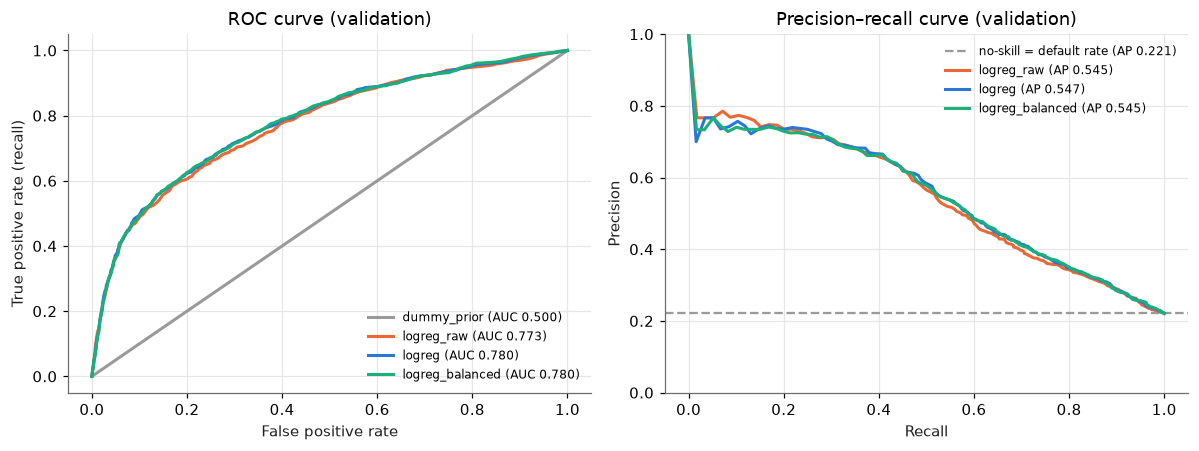

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for m in ORDER:
    c = records[m]["curves"]; pm = records[m]["probability_metrics"]
    axes[0].plot(c["roc_fpr"], c["roc_tpr"], color=COLOR[m], lw=2, label=f"{m} (AUC {pm['roc_auc']:.3f})")
    if m == "dummy_prior":  # constant scores: the PR "curve" is the horizontal no-skill line
        axes[1].axhline(pm["observed_default_rate"], color=GREY, ls="--", lw=1.5, label=f"no-skill = default rate (AP {pm['pr_auc']:.3f})")
    else:
        axes[1].plot(c["pr_recall"], c["pr_precision"], color=COLOR[m], lw=2, label=f"{m} (AP {pm['pr_auc']:.3f})")
axes[0].set(title="ROC curve (validation)", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].set(title="Precision–recall curve (validation)", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
for ax in axes: ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_roc_pr.png", bbox_inches="tight")

## Calibration: are the PDs trustworthy as probabilities?

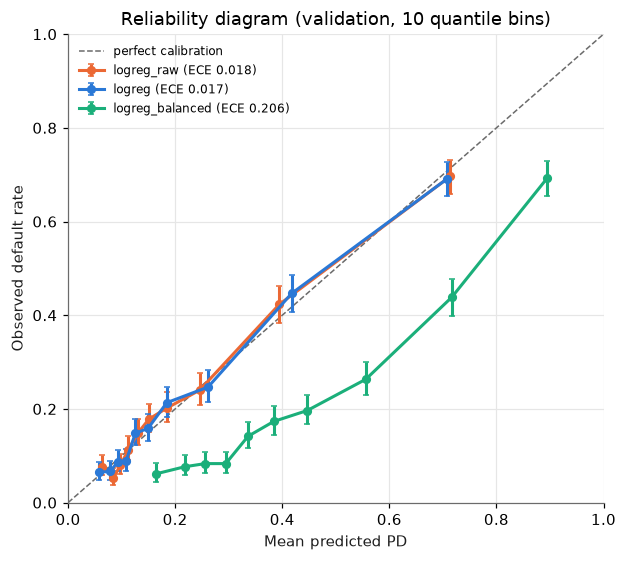

In [5]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="perfect calibration")
for m in ["logreg_raw", "logreg", "logreg_balanced"]:
    t = pd.DataFrame(records[m]["calibration_table"])
    ece = records[m]["probability_metrics"]["expected_calibration_error"]
    ax.errorbar(t["mean_predicted"], t["observed_rate"],
                yerr=[t["observed_rate"] - t["observed_low"], t["observed_high"] - t["observed_rate"]],
                color=COLOR[m], lw=2, marker="o", ms=5, capsize=2, label=f"{m} (ECE {ece:.3f})")
ax.set(title="Reliability diagram (validation, 10 quantile bins)", xlabel="Mean predicted PD", ylabel="Observed default rate", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_calibration.png", bbox_inches="tight")

`class_weight="balanced"` gives the same ranking quality (ROC-AUC difference ≈ 0) but **systematically inflates the PDs**. The mean predicted PD is about 0.43 against an observed rate of 0.22, and the Brier score is significantly worse. The reweighted scores are therefore not usable as probabilities without recalibration. Reweighting also adds nothing for threshold decisions: lowering the threshold on the unweighted model achieves the same trade-off.

## Threshold analysis for `logreg`

,threshold,tp,fp,tn,fn,precision,recall,f1,f2,flagged_rate
F2-optimal,0.11,1172.0,2665.0,2008.0,155.0,0.3054,0.8832,0.4539,0.6408,0.6395
F1-optimal,0.28,741.0,650.0,4023.0,586.0,0.5327,0.5584,0.5453,0.5531,0.2318
0.5,0.50,469.0,215.0,4458.0,858.0,0.6857,0.3534,0.4664,0.3914,0.1140


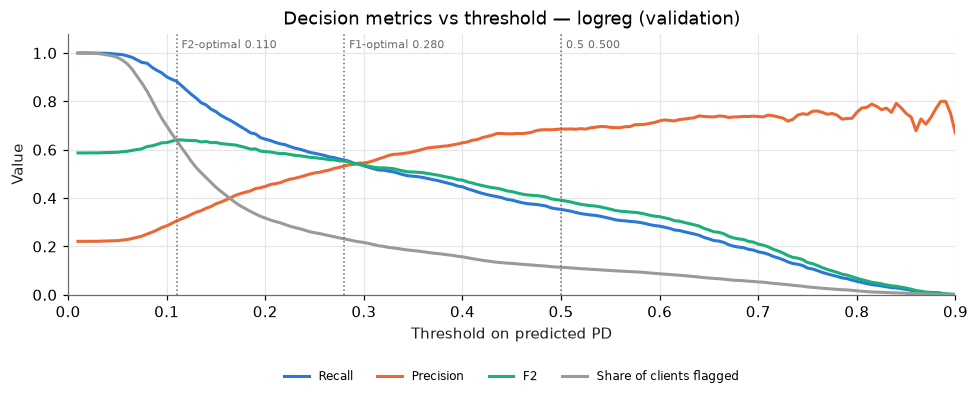

In [6]:
from credit_risk.decision_analysis import select_threshold, threshold_table
pred = pd.read_csv(resolve_path("artifacts/predictions/validation_logreg.csv"))
tt = threshold_table(pred["default_next_month"], pred["pd"])
f1_choice = select_threshold(pred["default_next_month"], pred["pd"], beta=1)
f2_choice = records["logreg"]["threshold_selection"]
fig, ax = plt.subplots(figsize=(9, 4))
for col, color, label in [("recall", BLUE, "Recall"), ("precision", ORANGE, "Precision"), ("f2", AQUA, "F2"), ("flagged_rate", GREY, "Share of clients flagged")]:
    ax.plot(tt["threshold"], tt[col], color=color, lw=2, label=label)
for choice, name in [(f2_choice, "F2-optimal"), (f1_choice, "F1-optimal"), ({"threshold": 0.5}, "0.5")]:
    ax.axvline(choice["threshold"], color=MUTED, lw=1, ls=":")
    ax.text(choice["threshold"] + 0.005, 1.02, f"{name} {choice['threshold']:.3f}", fontsize=7, color=MUTED)
ax.set(title="Decision metrics vs threshold — logreg (validation)", xlabel="Threshold on predicted PD", ylabel="Value", xlim=(0, 0.9), ylim=(0, 1.08))
ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.38))
fig.tight_layout(); fig.savefig(FIG_DIR / "03_threshold_curves.png", bbox_inches="tight")
pick = lambda t: tt.iloc[(tt["threshold"] - t).abs().argmin()]
pd.DataFrame({"F2-optimal": pick(f2_choice["threshold"]), "F1-optimal": pick(f1_choice["threshold"]), "0.5": pick(0.5)}).T

**Interpretation.** With a 22% default rate, F2 is maximised by a low threshold (~0.11) that flags almost two thirds of clients, so it catches about 88% of defaulters at about 31% precision. Even the no-skill rule "flag everyone" reaches F2 ≈ 0.59, because recall = 1. The model's F2 margin over that rule is small (≈ 0.05), even though its ranking skill is real (AUC 0.78 vs 0.50). The F2 objective therefore needs an operational constraint, such as a maximum share of clients flagged, or explicit costs. Otherwise the decision rule is close to rejecting most applicants.

## Logistic Regression coefficients (`logreg`, standardised inputs)

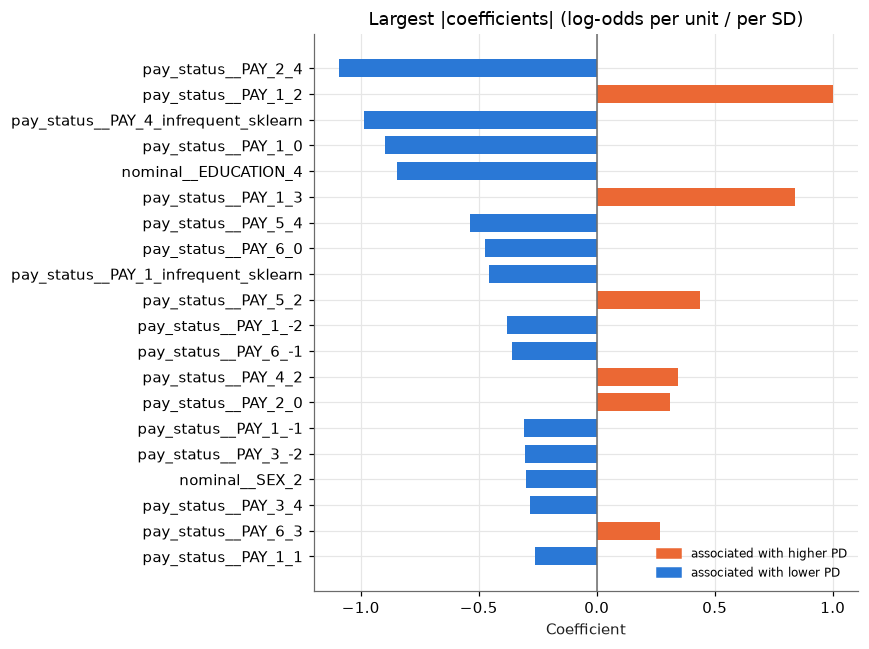

In [7]:
import joblib
model = joblib.load(resolve_path("artifacts/models/logreg.joblib"))
names = model.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(model.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20])[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.7)
ax.axvline(0, color=MUTED, lw=1)
ax.set(title="Largest |coefficients| (log-odds per unit / per SD)", xlabel="Coefficient")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["associated with higher PD", "associated with lower PD"], frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_logreg_coefficients.png", bbox_inches="tight")

Coefficients are **conditional associations** given the other inputs. Many inputs are strongly correlated (monthly bills, the delay codes and their counts), so individual signs can flip and should not be read as causal effects or as stand-alone risk drivers. SHAP analysis follows in Phase 4.

## Fairness diagnostics (`logreg`, validation, at the F2 threshold)

In [8]:
for key in ["SEX", "AGE_BAND"]:
    print(key, "(SEX: 1 = male, 2 = female)" if key == "SEX" else "")
    display(pd.DataFrame(records["logreg"]["group_metrics"][key]).set_index("group"))

SEX (SEX: 1 = male, 2 = female)


,count,observed_default_rate,mean_predicted_pd,flagged_rate,recall,false_positive_rate,roc_auc
group,,,,,,,
1,2385,0.2545,0.2384,0.7002,0.9028,0.631,0.7693
2,3615,0.1992,0.2052,0.5994,0.8667,0.533,0.7835


AGE_BAND 


,count,observed_default_rate,mean_predicted_pd,flagged_rate,recall,false_positive_rate,roc_auc
group,,,,,,,
"[20, 30)",1878,0.2151,0.2254,0.6624,0.9084,0.5950,0.7853
"[30, 40)",2274,0.2005,0.2060,0.5972,0.8640,0.5303,0.7840
"[40, 50)",1318,0.2473,0.2242,0.6525,0.8834,0.5766,0.7771
"[50, 60)",462,0.2489,0.2259,0.7035,0.8696,0.6484,0.7351
"[60, 80)",68,0.3824,0.2779,0.7353,0.8846,0.6429,0.7720


Calibration-in-the-large is reasonable across groups (mean PD close to the observed rate). Error rates differ, though: men (SEX = 1) are flagged more often, with a higher false-positive rate, consistent with their higher observed default rate. The 60+ band is small (n = 68), and its PD is under-predicted (0.28 vs 0.38 observed, a very wide interval at this size). These are descriptive diagnostics, not a fair-lending assessment.

## Summary of Phase 2 (validation results)
1. **Logistic Regression clearly beats the no-skill baseline.** ROC-AUC 0.780 [0.765, 0.794] vs 0.5, and Brier 0.1345 vs 0.1723.
2. **Engineered features give a small but statistically detectable gain** in ROC-AUC (+0.0066, paired 95% CI [+0.0034, +0.0102]) and Brier score. The PR-AUC gain is not significant.
3. **Class reweighting doesn't improve ranking and badly damages calibration.** It is not adopted.
4. **The F2-optimal threshold flags ~64% of clients.** The decision objective needs an operational constraint (see the notes above).